# Phase 1 (Grade 3.0) — Basic Unconditional GAN on EMNIST Letters

> **Team Members:** `[Student 1 Name — Student ID]` & `[Student 2 Name — Student ID]`  
> **Course:** Deep Learning Labs (PUT)  
> **Goal:** Implement and train an unconditional Generative Adversarial Network (GAN) that generates realistic `28x28` handwritten letter images from random noise.

### Notebook Outline
1. **Dataset Exploration & Pitfalls** — fixing EMNIST's transposed orientation and 1-indexed labels.
2. **Trial 1: MLP GAN (Baseline)** — a simple fully connected GAN to establish a baseline and observe its limitations.
3. **Trial 2: Compact DCGAN (Final Phase 1 Model)** — upgrading to convolutional layers, DCGAN weight initialization, and one-sided label smoothing.
4. **Final Showcase & Latent Space Interpolation** — checking visual quality, diversity, and smoothness of the learned latent space.

In [1]:
import sys
from pathlib import Path

# Ensure the repository root is on sys.path whether Jupyter starts in root or notebooks/
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import torch

from src.dataset import get_emnist_dataloader, get_emnist_dataset, label_to_letter
from src.models import (
    DCGANDiscriminator,
    DCGANGenerator,
    MLPDiscriminator,
    MLPGenerator,
    init_gan_weights,
)
from src.train import train_unconditional_gan
from src.utils import (
    denormalize,
    get_device,
    plot_training_losses,
    save_checkpoint,
    set_seed,
    show_image_grid,
)

DATA_DIR = PROJECT_ROOT / "data"
CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "phase1"

set_seed(42)
device = get_device()
print(f"Project root: {PROJECT_ROOT}")
print(f"Using device: {device}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

/home/mateusz/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-ghwy3qw7 because there was an issue with the default path (/home/mateusz/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


/home/mateusz/code/GAN/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /home/mateusz/code/GAN
Using device: cuda
GPU: NVIDIA GeForce RTX 5070 Laptop GPU


## 1. Exploring EMNIST Letters & Fixing Dataset Quirks

Before training any GAN, we inspected real samples from `torchvision.datasets.EMNIST(split="letters")` and caught **two common pitfalls**:

1. **Transposed image orientation:** By default, EMNIST images come rotated 90° and flipped horizontally (a carryover from the original MATLAB format). Transposing the height and width axes (`image.transpose(1, 2)`) makes all letters upright.
2. **1-indexed labels:** Class `0` is unused (`N/A`), and letters `'A'..'Z'` are numbered `1..26`. Shifting labels by `-1` maps them cleanly to `0..25` (important for Phase 2 embeddings).
3. **Pixel range `[-1, 1]`:** We normalize images with `mean=0.5, std=0.5` so real data matches our Generator's `Tanh()` output range.

Below we visualize the raw images vs. the fixed images to confirm our preprocessing pipeline.

Training set size: 124,800 images
Single image shape: (1, 28, 28)
Pixel value range: [-1.00, 1.00]
Shifted label range: 6..25 (letters: ['W', 'G', 'P', 'O', 'W', 'Q', 'M', 'K'])


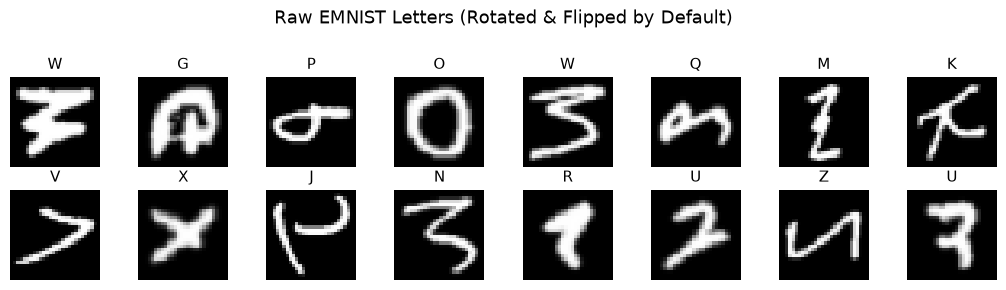

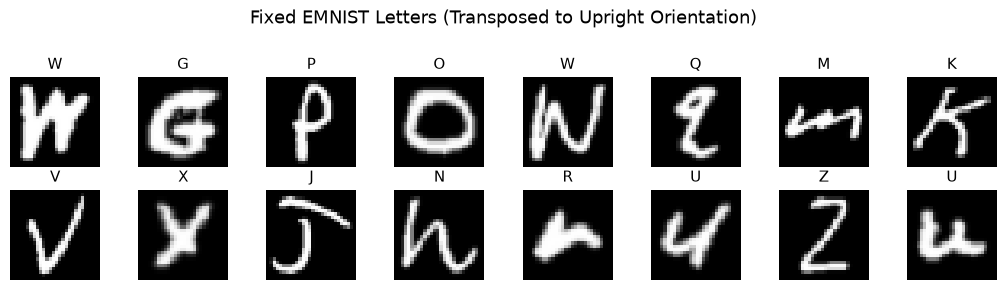

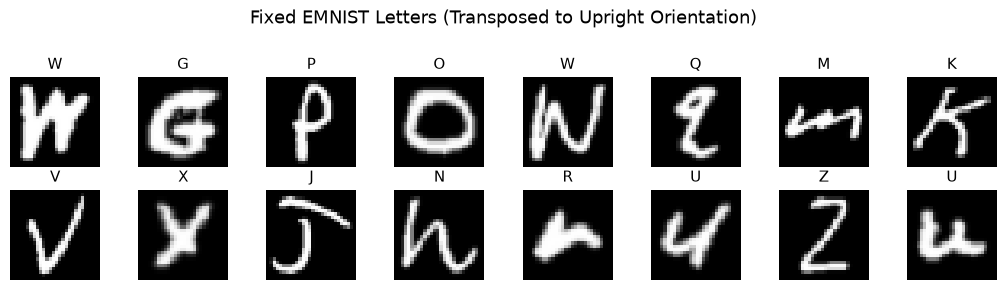

In [2]:
raw_dataset = get_emnist_dataset(root=DATA_DIR, train=True, download=True, fix_orientation=False)
fixed_dataset = get_emnist_dataset(root=DATA_DIR, train=True, download=True, fix_orientation=True)

sample_indices = list(range(16))
raw_images = torch.stack([raw_dataset[i][0] for i in sample_indices])
fixed_images = torch.stack([fixed_dataset[i][0] for i in sample_indices])
sample_labels = [fixed_dataset[i][1] for i in sample_indices]

print(f"Training set size: {len(fixed_dataset):,} images")
print(f"Single image shape: {tuple(fixed_images[0].shape)}")
print(f"Pixel value range: [{fixed_images.min():.2f}, {fixed_images.max():.2f}]")
print(f"Shifted label range: {min(sample_labels)}..{max(sample_labels)} (letters: {[label_to_letter(y) for y in sample_labels[:8]]})")

show_image_grid(
    raw_images,
    labels=sample_labels,
    nrow=8,
    title="Raw EMNIST Letters (Rotated & Flipped by Default)",
)
show_image_grid(
    fixed_images,
    labels=sample_labels,
    nrow=8,
    title="Fixed EMNIST Letters (Transposed to Upright Orientation)",
    save_path=OUTPUT_DIR / "real_emnist_samples.png",
)

## 2. How Our Unconditional GAN Works

A GAN trains two competing neural networks in alternating steps:

- **Generator $G(z)$:** Takes a random noise vector $z \sim \mathcal{N}(0, I_{64})$ and produces a fake `1x28x28` letter image.
- **Discriminator $D(x)$:** Takes a real or generated image $x$ and outputs a logit predicting whether $x$ is real (`1`) or fake (`0`).

Both networks are optimized using `nn.BCEWithLogitsLoss()`:
- **Discriminator step:** Push $D(x_{\text{real}}) \to 1$ (or `0.9` with label smoothing) and $D(G(z)) \to 0$.
- **Generator step:** Push $D(G(z)) \to 1$ so the fake images fool the Discriminator.

To compare models and epochs fairly, we create one shared batch of 32 fixed noise vectors (`fixed_z`) and track how the exact same noise vectors evolve during training.

In [3]:
BATCH_SIZE = 128
LATENT_DIM = 64

train_loader = get_emnist_dataloader(
    batch_size=BATCH_SIZE,
    train=True,
    root=DATA_DIR,
    num_workers=2,
    download=True,
)

set_seed(42)
fixed_z = torch.randn(32, LATENT_DIM, device=device)
print(f"Batches per epoch: {len(train_loader)} (batch_size={BATCH_SIZE})")

Batches per epoch: 975 (batch_size=128)


## 3. Trial 1 — Simple MLP (Fully Connected) GAN Baseline

As our first experiment, we try the simplest possible GAN architecture: a 3-layer **Multi-Layer Perceptron (MLP)** for both Generator and Discriminator (`784` flattened pixels), trained with standard binary labels (`real = 1.0`, `fake = 0.0`).

This gives us a fast baseline to see what works and where a purely fully connected architecture struggles on handwritten letters.

In [4]:
set_seed(42)
mlp_G = MLPGenerator(latent_dim=LATENT_DIM)
mlp_D = MLPDiscriminator()

print(f"MLP Generator params:     {sum(p.numel() for p in mlp_G.parameters()):,}")
print(f"MLP Discriminator params: {sum(p.numel() for p in mlp_D.parameters()):,}")

mlp_history = train_unconditional_gan(
    generator=mlp_G,
    discriminator=mlp_D,
    dataloader=train_loader,
    device=device,
    epochs=15,
    latent_dim=LATENT_DIM,
    lr=2e-4,
    betas=(0.5, 0.999),
    real_label_value=1.0,  # No label smoothing in our naive baseline
    fixed_noise=fixed_z,
    snapshot_epochs=(1, 5, 15),
    show_progress=False,
)

save_checkpoint(
    CHECKPOINT_DIR / "phase1_mlp_gan.pt",
    generator=mlp_G,
    discriminator=mlp_D,
    epoch=15,
    history=mlp_history,
    config={"model": "MLP", "latent_dim": LATENT_DIM, "real_label_value": 1.0},
)

MLP Generator params:     551,952
MLP Discriminator params: 533,505


Epoch 01/15 | D loss: 1.0554 | G loss: 1.2429 | D(real): 0.674 | D(fake): 0.426


Epoch 02/15 | D loss: 0.9989 | G loss: 1.3904 | D(real): 0.672 | D(fake): 0.358


Epoch 03/15 | D loss: 1.0421 | G loss: 1.3072 | D(real): 0.651 | D(fake): 0.362


Epoch 04/15 | D loss: 1.0429 | G loss: 1.3011 | D(real): 0.649 | D(fake): 0.359


Epoch 05/15 | D loss: 1.0367 | G loss: 1.3057 | D(real): 0.651 | D(fake): 0.356


... (7 outputs left out)

Epoch 13/15 | D loss: 1.2172 | G loss: 0.9881 | D(real): 0.578 | D(fake): 0.423


Epoch 14/15 | D loss: 1.2218 | G loss: 0.9834 | D(real): 0.576 | D(fake): 0.425


Epoch 15/15 | D loss: 1.2233 | G loss: 0.9776 | D(real): 0.575 | D(fake): 0.425


PosixPath('/home/mateusz/code/GAN/checkpoints/phase1_mlp_gan.pt')

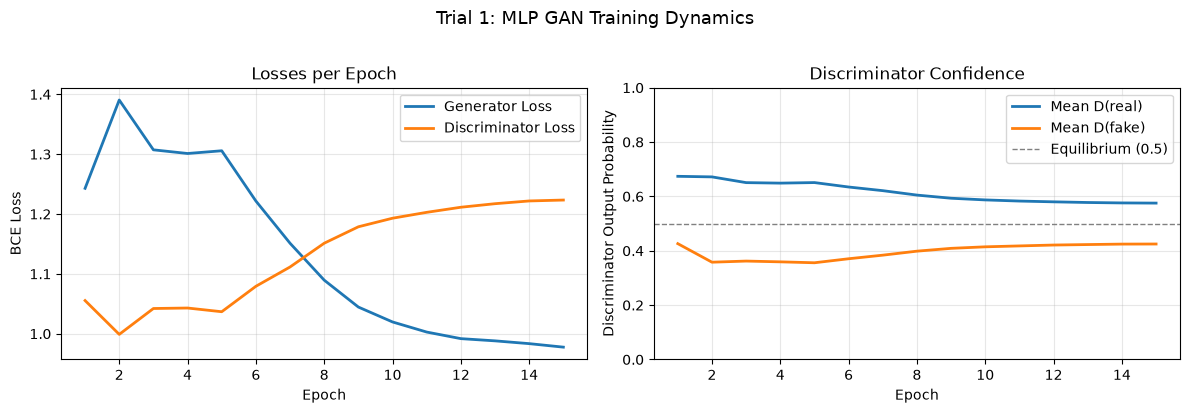

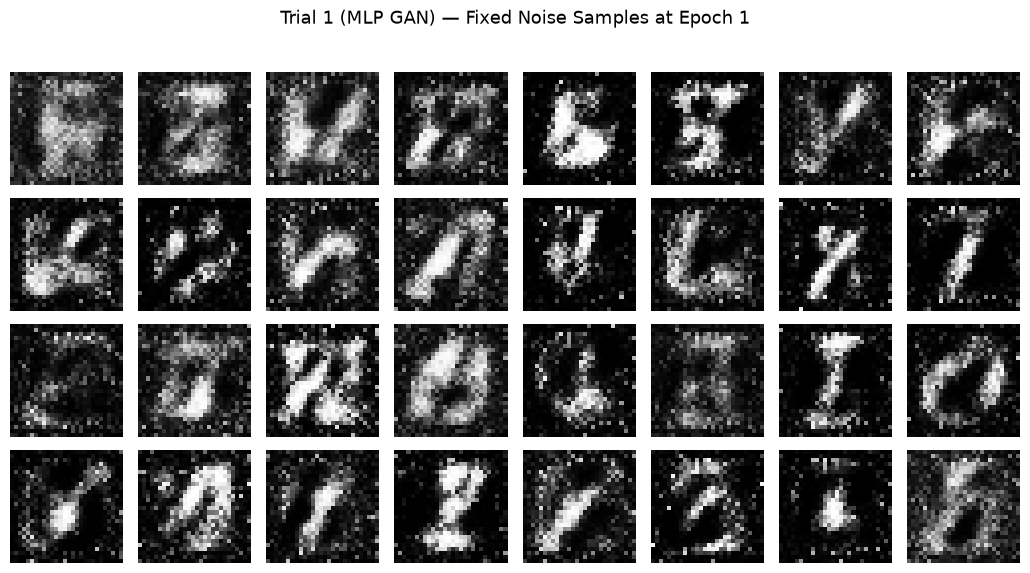

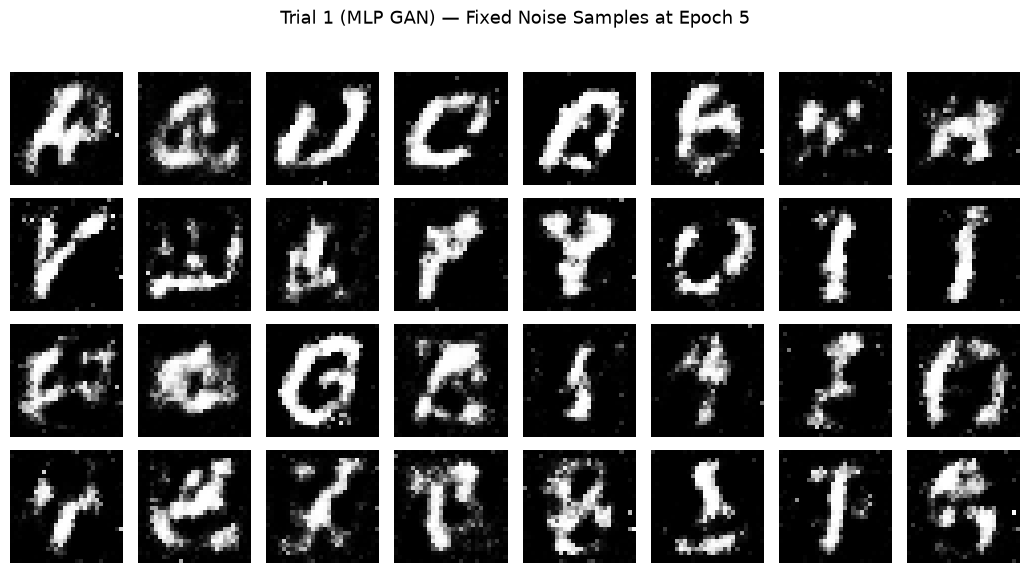

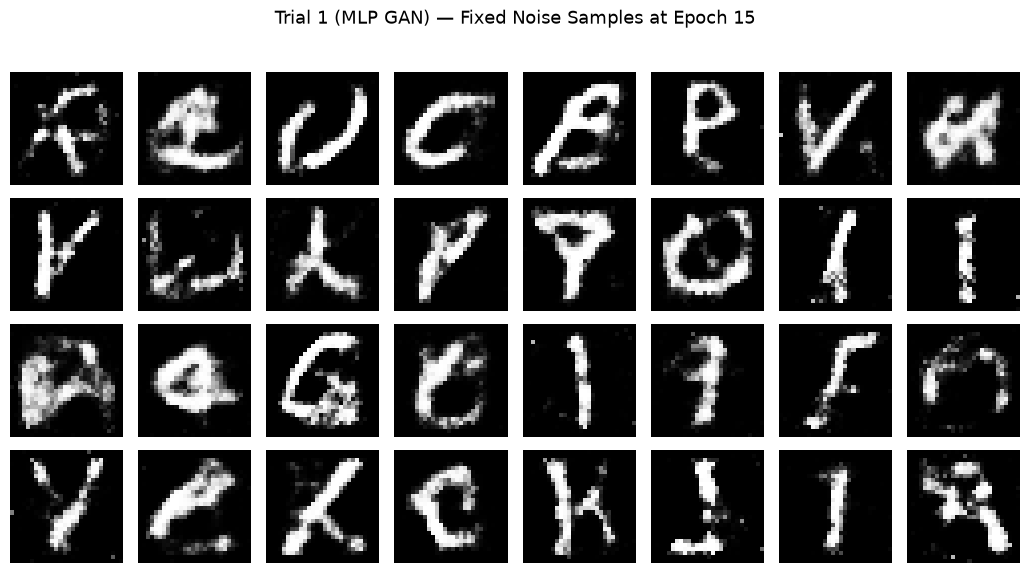

In [5]:
plot_training_losses(
    mlp_history["g_losses"],
    mlp_history["d_losses"],
    mlp_history["d_real_scores"],
    mlp_history["d_fake_scores"],
    title="Trial 1: MLP GAN Training Dynamics",
    save_path=OUTPUT_DIR / "trial1_mlp_losses.png",
)

for epoch in (1, 5, 15):
    show_image_grid(
        mlp_history["snapshots"][epoch],
        nrow=8,
        title=f"Trial 1 (MLP GAN) — Fixed Noise Samples at Epoch {epoch}",
        save_path=OUTPUT_DIR / f"trial1_mlp_epoch_{epoch:02d}.png",
    )

### Observations from Trial 1 (MLP Baseline)

- **What worked:** The MLP GAN learns rough letter-like blobs quickly and does not diverge.
- **What went wrong / limitations:**
  - Because the image is flattened into a 784-element vector, the network has **no spatial inductive bias** (it does not know which pixels are neighbors). As a result, generated strokes look grainy and speckled around the edges.
  - Many letters appear blurry, fragmented, or ambiguous.
- **Planned improvement for Trial 2:** Replace linear layers with **2D convolutions (`Conv2d`) and transposed convolutions (`ConvTranspose2d`)** following the **DCGAN** design, apply `Normal(0, 0.02)` weight initialization, and add **one-sided label smoothing** (`real_label_value=0.9`) to keep the Discriminator from becoming overconfident.

## 4. Trial 2 — Compact DCGAN (Final Phase 1 Model)

Our convolutional architecture is tailored specifically for `1x28x28` images:

- **Generator $G(z)$:** `Linear(64 -> 128*7*7)` $\rightarrow$ `BatchNorm2d + ReLU` $\rightarrow$ `ConvTranspose2d(128 -> 64, 14x14)` $\rightarrow$ `BatchNorm2d + ReLU` $\rightarrow$ `ConvTranspose2d(64 -> 1, 28x28)` $\rightarrow$ `Tanh()`.
- **Discriminator $D(x)$:** `Conv2d(1 -> 64, 14x14)` $\rightarrow$ `LeakyReLU(0.2)` $\rightarrow$ `Conv2d(64 -> 128, 7x7)` $\rightarrow$ `BatchNorm2d + LeakyReLU(0.2)` $\rightarrow$ `Flatten -> Linear(128*7*7 -> 1)`.

Key stability choices:
- **DCGAN weight initialization:** `Normal(0, 0.02)` on Conv/Linear weights.
- **Adam optimizer:** `lr = 2e-4`, `betas = (0.5, 0.999)`.
- **One-sided label smoothing:** Real targets set to `0.9` instead of `1.0`.

In [6]:
set_seed(42)
dcgan_G = DCGANGenerator(latent_dim=LATENT_DIM, base_channels=64)
dcgan_D = DCGANDiscriminator(base_channels=64)

dcgan_G.apply(init_gan_weights)
dcgan_D.apply(init_gan_weights)

print(f"DCGAN Generator params:     {sum(p.numel() for p in dcgan_G.parameters()):,}")
print(f"DCGAN Discriminator params: {sum(p.numel() for p in dcgan_D.parameters()):,}")

dcgan_history = train_unconditional_gan(
    generator=dcgan_G,
    discriminator=dcgan_D,
    dataloader=train_loader,
    device=device,
    epochs=25,
    latent_dim=LATENT_DIM,
    lr=2e-4,
    betas=(0.5, 0.999),
    real_label_value=0.9,  # One-sided label smoothing
    fixed_noise=fixed_z,
    snapshot_epochs=(1, 5, 10, 15, 25),
    show_progress=False,
)

save_checkpoint(
    CHECKPOINT_DIR / "phase1_dcgan.pt",
    generator=dcgan_G,
    discriminator=dcgan_D,
    epoch=25,
    history=dcgan_history,
    config={"model": "DCGAN", "latent_dim": LATENT_DIM, "real_label_value": 0.9},
)

DCGAN Generator params:     533,888
DCGAN Discriminator params: 138,689


Epoch 01/25 | D loss: 0.7028 | G loss: 2.1356 | D(real): 0.728 | D(fake): 0.177


Epoch 02/25 | D loss: 0.7746 | G loss: 1.8799 | D(real): 0.696 | D(fake): 0.204


Epoch 03/25 | D loss: 0.7857 | G loss: 1.9242 | D(real): 0.696 | D(fake): 0.202


Epoch 04/25 | D loss: 0.7592 | G loss: 2.0536 | D(real): 0.712 | D(fake): 0.188


Epoch 05/25 | D loss: 0.7534 | G loss: 2.0949 | D(real): 0.714 | D(fake): 0.186


... (17 outputs left out)

Epoch 23/25 | D loss: 0.6258 | G loss: 2.7947 | D(real): 0.780 | D(fake): 0.120


Epoch 24/25 | D loss: 0.6031 | G loss: 2.8550 | D(real): 0.788 | D(fake): 0.112


Epoch 25/25 | D loss: 0.6754 | G loss: 2.7282 | D(real): 0.769 | D(fake): 0.131


PosixPath('/home/mateusz/code/GAN/checkpoints/phase1_dcgan.pt')

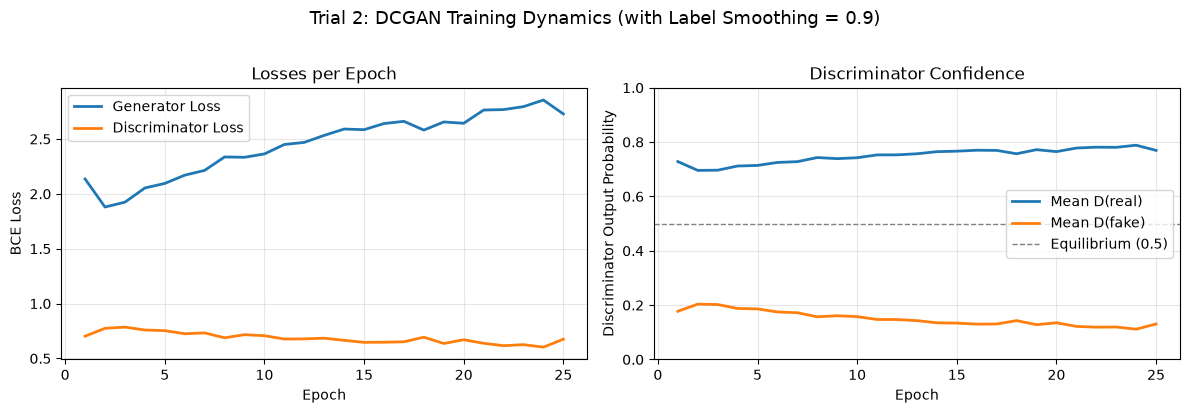

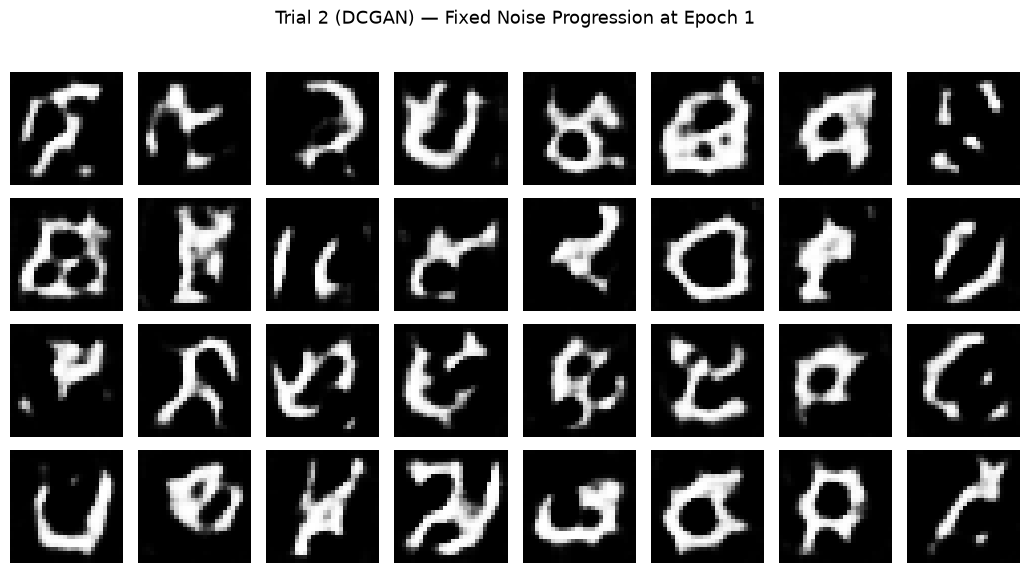

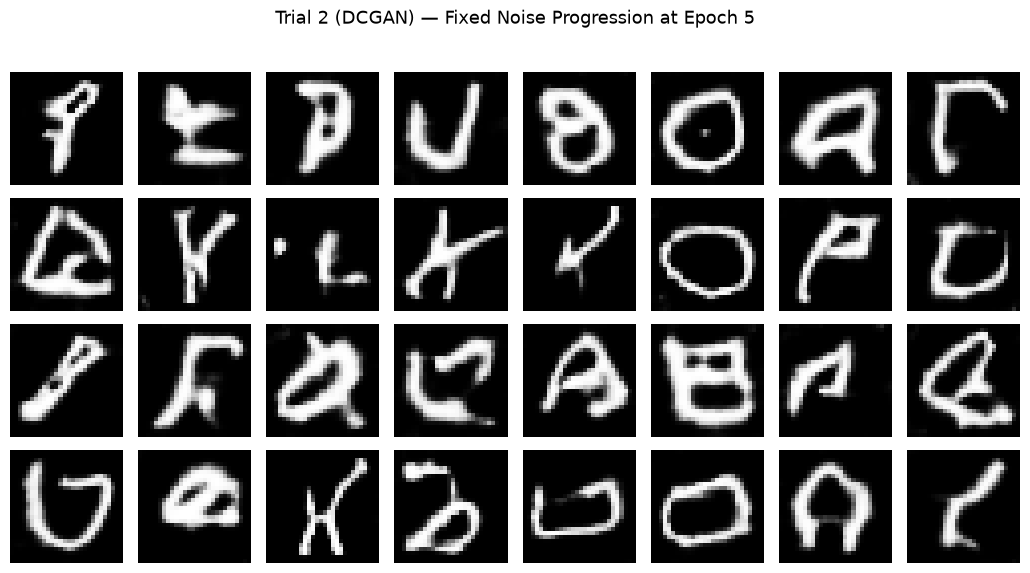

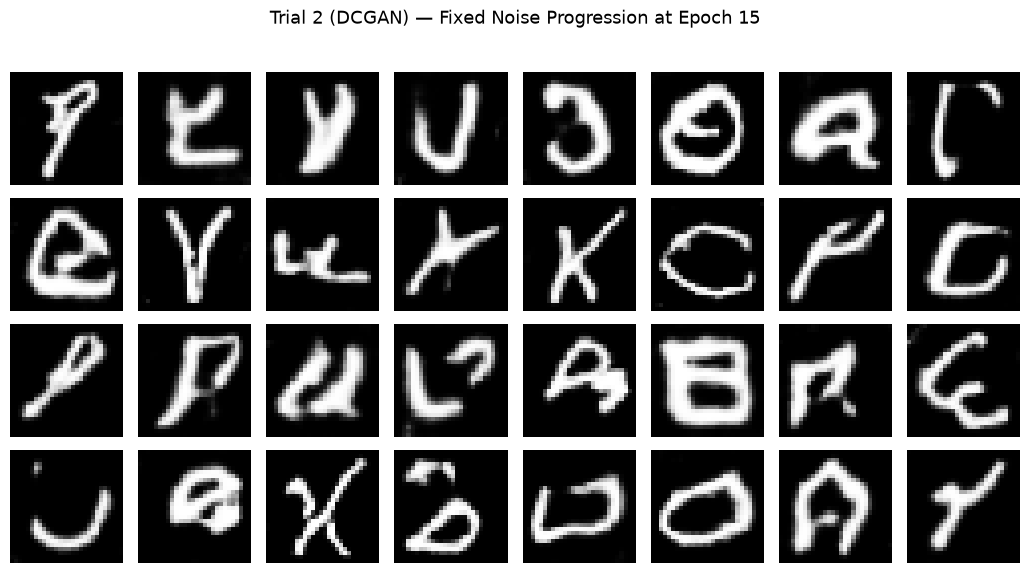

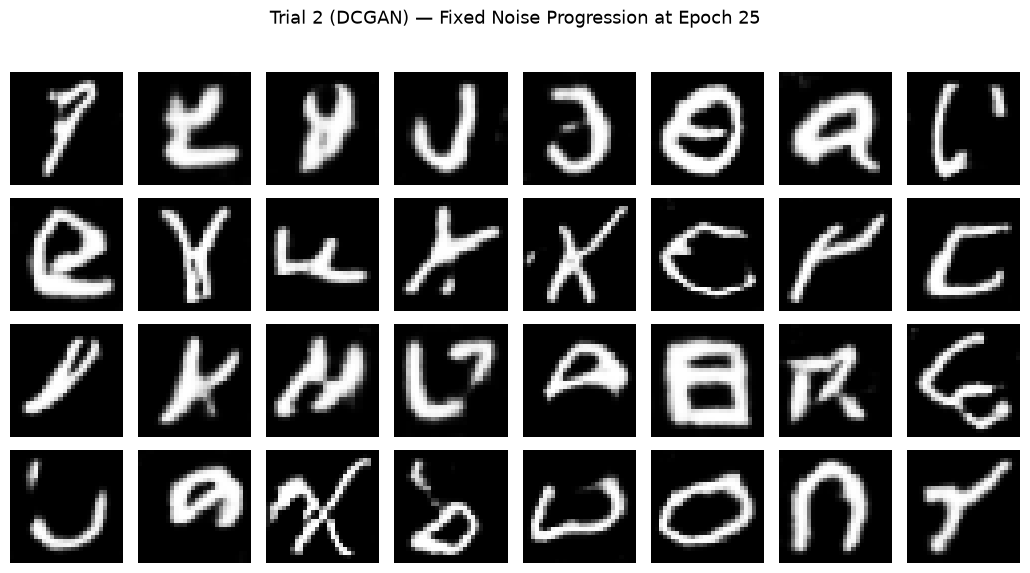

In [7]:
plot_training_losses(
    dcgan_history["g_losses"],
    dcgan_history["d_losses"],
    dcgan_history["d_real_scores"],
    dcgan_history["d_fake_scores"],
    title="Trial 2: DCGAN Training Dynamics (with Label Smoothing = 0.9)",
    save_path=OUTPUT_DIR / "trial2_dcgan_losses.png",
)

for epoch in (1, 5, 15, 25):
    show_image_grid(
        dcgan_history["snapshots"][epoch],
        nrow=8,
        title=f"Trial 2 (DCGAN) — Fixed Noise Progression at Epoch {epoch}",
        save_path=OUTPUT_DIR / f"trial2_dcgan_epoch_{epoch:02d}.png",
    )

### Observations from Trial 2 (DCGAN)

- **Visual quality jump:** Compared to the MLP baseline in Trial 1, the convolutional DCGAN produces clean black backgrounds, continuous strokes, and much sharper letter shapes across the fixed noise samples.
- **Training dynamics:** With one-sided label smoothing (`0.9`), training stayed stable across all 25 epochs without mode collapse. `Mean D(real)` stayed around `0.75-0.79` and `Mean D(fake)` around `0.11-0.20`, meaning the Discriminator stayed slightly ahead of the Generator (causing `G loss` to rise gently from `~1.9` to `~2.7`), while still providing informative gradients.
- **Why a few samples look hybrid/ambiguous:** EMNIST Letters merges uppercase and lowercase forms across 26 classes without conditioning here, so an unconditional Generator occasionally blends strokes between visually similar letters (a limitation Phase 2 will directly address with class conditioning).

## 5. Final Showcase & Latent Space Interpolation

Finally, we run two qualitative checks on our trained DCGAN:
1. **Fresh sample grid (64 random letters):** Verify visual sharpness and broad diversity across the alphabet (no mode collapse).
2. **Latent space interpolation:** Linearly interpolate between pairs of random noise vectors $z_a$ and $z_b$ via $z(\alpha) = (1 - \alpha) z_a + \alpha z_b$. Smooth morphing between letters shows the Generator learned a continuous representation of handwriting rather than memorizing individual training images.

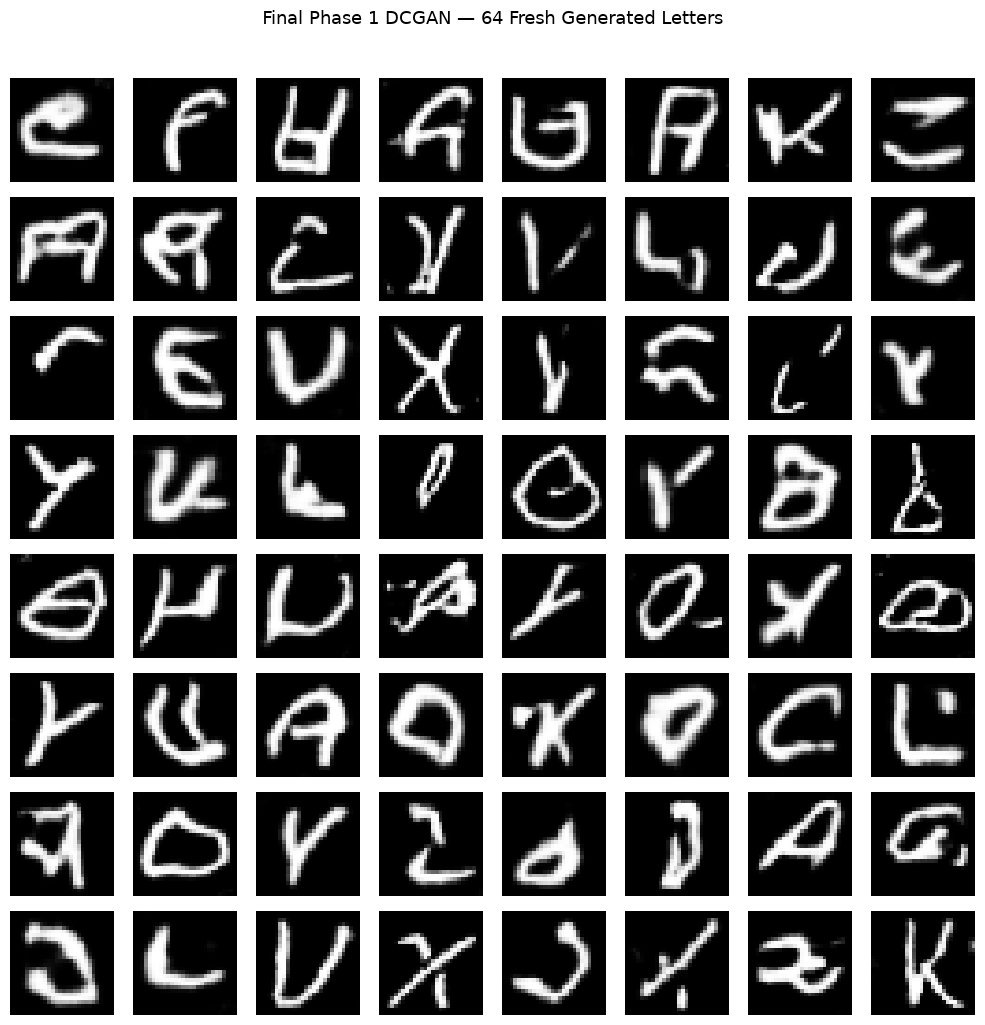

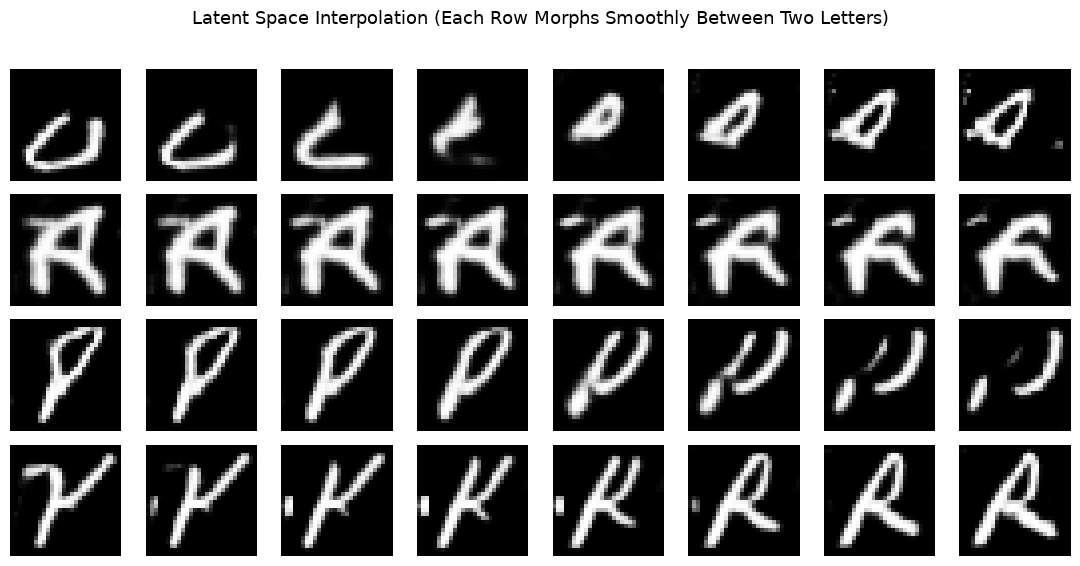

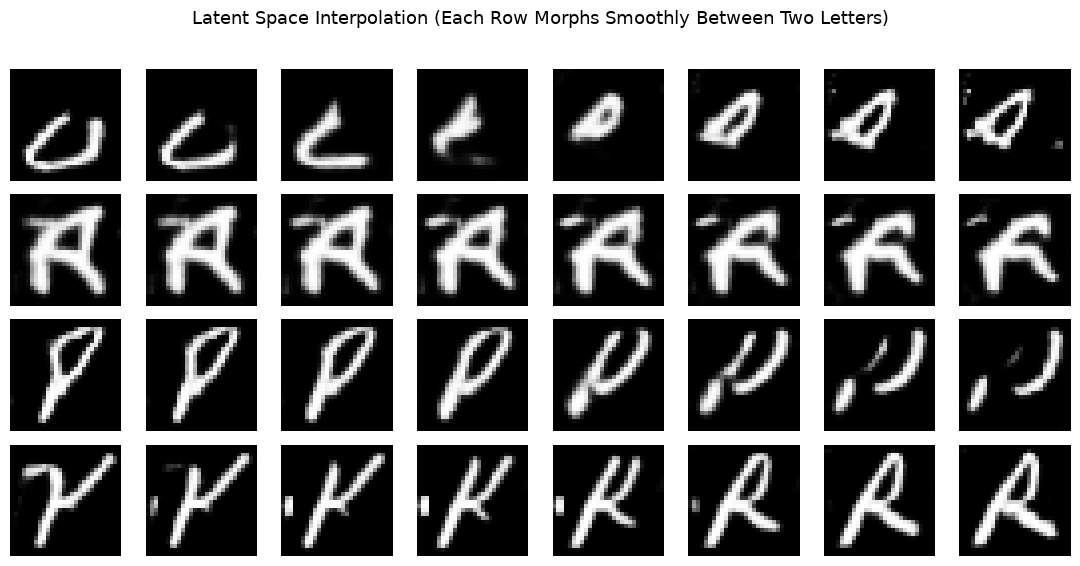

In [8]:
dcgan_G.eval()
set_seed(123)

with torch.no_grad():
    fresh_z = torch.randn(64, LATENT_DIM, device=device)
    fresh_samples = dcgan_G(fresh_z).cpu()

show_image_grid(
    fresh_samples,
    nrow=8,
    title="Final Phase 1 DCGAN — 64 Fresh Generated Letters",
    figsize=(10, 10),
    save_path=OUTPUT_DIR / "phase1_final_samples.png",
)

# Latent space interpolation: 4 rows x 8 interpolation steps
num_pairs = 4
num_steps = 8
alphas = torch.linspace(0.0, 1.0, num_steps, device=device)

with torch.no_grad():
    z_start = torch.randn(num_pairs, LATENT_DIM, device=device)
    z_end = torch.randn(num_pairs, LATENT_DIM, device=device)

    interp_images = []
    for i in range(num_pairs):
        row_z = torch.stack([(1 - a) * z_start[i] + a * z_end[i] for a in alphas])
        interp_images.append(dcgan_G(row_z).cpu())
    interp_grid = torch.cat(interp_images, dim=0)

show_image_grid(
    interp_grid,
    nrow=num_steps,
    title="Latent Space Interpolation (Each Row Morphs Smoothly Between Two Letters)",
    figsize=(11, 5.5),
    save_path=OUTPUT_DIR / "phase1_latent_interpolation.png",
)

## 6. Phase 1 Summary & Next Steps

| Experiment | Architecture | Label Smoothing | Result |
| :--- | :--- | :--- | :--- |
| **Trial 1** | 3-layer MLP GAN | None (`1.0`) | Learns rough shapes quickly, but produces grainy backgrounds and soft/blurry edges. |
| **Trial 2 (Final)** | Compact `28x28` DCGAN | One-sided (`0.9`) | Clean dark backgrounds, sharp continuous strokes, diverse uppercase/lowercase letters, smooth latent interpolations. |

### Ready for Phase 2 (Grade 4.0)
Right now our Generator chooses *which* letter to draw purely at random based on $z$. In **Phase 2**, we will extend this exact DCGAN backbone by adding a learnable `nn.Embedding(26, 32)` vector so the user can specify any letter `'A'..'Z'` (or even a whole word!) and generate handwritten samples of it on demand.